# Telco Customer Churn Predictor

## One guided beginner project

This notebook goes from business question to a saved model. It includes basic classification, cross-validation, a small hyperparameter search, ensemble learning, and a simple final model choice.

**There is one train/test split.** Cross-validation and tuning reuse only the training portion; the test portion is kept aside and evaluated once at the end. No extra validation dataset or intermediate split files are created.

### Why churn matters

Telecom companies earn recurring revenue while customers stay. They also spend money to acquire customers and may spend more on retention offers or support. A churn prediction can help a team decide who to contact first, but it cannot tell us why a customer leaves or prove an offer will keep them.

**Example:** if a customer contributes $40 per month and leaves nine months earlier than expected, up to $360 of possible contribution may be at risk. A retention offer only makes sense if it helps keep the customer and costs less than the value it preserves.

### Dataset

We use IBM's public Telco Customer Churn sample. Each row represents a customer of a fictional telecom provider, and `Churn` indicates whether that customer left within the last month. The dataset is available in [IBM's repository](https://github.com/IBM/telco-customer-churn-on-icp4d) and on [Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). The CSV is stored in `data/telco_churn.csv`.

## 1. Load and inspect the customers

We first look at the size, columns, data types, blanks, and duplicates. Notebook 1's exploratory charts use the complete dataset before we create the test set; model fitting, model comparison, and tuning use only the training portion.

In [1]:
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

CURRENT_FOLDER = Path.cwd()
PROJECT_FOLDER = CURRENT_FOLDER.parent if CURRENT_FOLDER.name.lower() == "notebooks" else CURRENT_FOLDER
DATA_PATH = PROJECT_FOLDER / "data" / "telco_churn.csv"
MODEL_PATH = PROJECT_FOLDER / "models" / "churn_model.joblib"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

customers = pd.read_csv(DATA_PATH)
print(f"Rows: {customers.shape[0]:,}")
print(f"Columns: {customers.shape[1]}")
customers.head()

Rows: 7,043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Column data types:")
display(customers.dtypes.astype(str).rename("data_type").to_frame())

print("Missing values recognized by pandas:")
display(customers.isna().sum().rename("missing_rows").to_frame())

print("Exact duplicate rows:", int(customers.duplicated().sum()))

Column data types:


,data_type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


Missing values recognized by pandas:


,missing_rows
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Exact duplicate rows: 0


## 2. Understand the churn target and customer groups

The target is a little imbalanced: fewer customers churn than stay. If a model always predicts “No churn,” its accuracy looks fairly high even though it finds no churners. We will keep track of precision and recall as well as accuracy.

,customers,share_percent
Churn,,
No,5174,73.5
Yes,1869,26.5


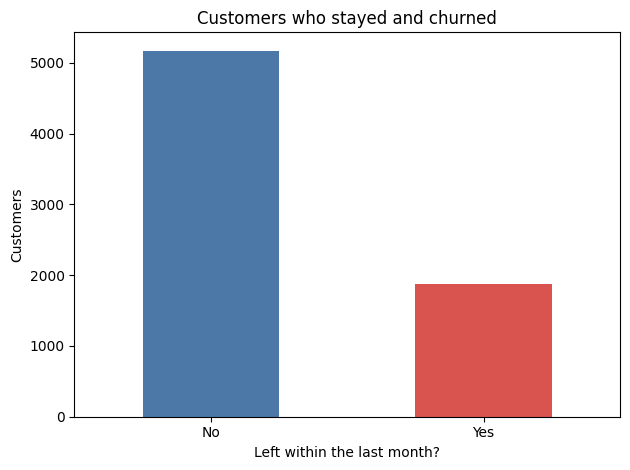

Always predicting 'No' would have 73.5% accuracy and 0% churn recall.


In [3]:
churn_counts = customers["Churn"].value_counts().reindex(["No", "Yes"])
churn_share = customers["Churn"].value_counts(normalize=True).reindex(["No", "Yes"])
display(pd.DataFrame({
    "customers": churn_counts,
    "share_percent": (churn_share * 100).round(1),
}))

ax = churn_counts.plot(kind="bar", color=["#4C78A8", "#D9534F"], rot=0)
ax.set(title="Customers who stayed and churned", xlabel="Left within the last month?", ylabel="Customers")
plt.tight_layout()
plt.show()
print(f"Always predicting 'No' would have {customers['Churn'].eq('No').mean():.1%} accuracy and 0% churn recall.")

In [4]:
def churn_rate_by(feature_name):
    summary = customers.groupby(feature_name).agg(
        customers=("Churn", "size"),
        churn_rate=("Churn", lambda values: values.eq("Yes").mean()),
    )
    summary["churn_rate_percent"] = (summary["churn_rate"] * 100).round(1)
    return summary.sort_values("churn_rate", ascending=False)

for feature_name in ["Contract", "PaymentMethod", "InternetService"]:
    print(f"Observed churn by {feature_name}")
    display(churn_rate_by(feature_name))

print("Median tenure by churn outcome:")
display(customers.groupby("Churn")["tenure"].median().rename("median_months").to_frame())

Observed churn by Contract


,customers,churn_rate,churn_rate_percent
Contract,,,
Month-to-month,3875,0.427097,42.7
One year,1473,0.112695,11.3
Two year,1695,0.028319,2.8


Observed churn by PaymentMethod


,customers,churn_rate,churn_rate_percent
PaymentMethod,,,
Electronic check,2365,0.452854,45.3
Mailed check,1612,0.191067,19.1
Bank transfer (automatic),1544,0.167098,16.7
Credit card (automatic),1522,0.152431,15.2


Observed churn by InternetService


,customers,churn_rate,churn_rate_percent
InternetService,,,
Fiber optic,3096,0.418928,41.9
DSL,2421,0.189591,19.0
No,1526,0.074050,7.4


Median tenure by churn outcome:


,median_months
Churn,
No,38.0
Yes,10.0


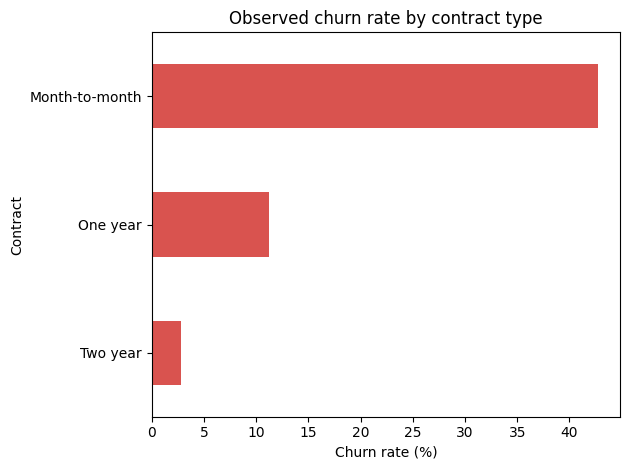

In [5]:
contract_rates = churn_rate_by("Contract")["churn_rate"] * 100
ax = contract_rates.sort_values().plot(kind="barh", color="#D9534F")
ax.set(title="Observed churn rate by contract type", xlabel="Churn rate (%)", ylabel="Contract")
plt.tight_layout()
plt.show()

These segment rates are descriptions of this sample, not proof that changing a contract or payment method will prevent churn. We will use the information as context and let the model learn patterns from training customers.

## 3. Clean the billing column

`TotalCharges` is stored as text. We found 11 blank strings, all for customers with zero months of tenure. We convert the column to numbers and replace those confirmed blanks with 0.

In [6]:
blank_total_charges = customers["TotalCharges"].astype(str).str.strip().eq("")
print("Blank TotalCharges rows:", int(blank_total_charges.sum()))
display(customers.loc[blank_total_charges, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Blank TotalCharges rows: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [7]:
customers["TotalCharges"] = pd.to_numeric(
    customers["TotalCharges"].astype(str).str.strip(),
    errors="coerce",
)
blank_charge_rows = customers["TotalCharges"].isna()
if (blank_charge_rows & customers["tenure"].ne(0)).any():
    raise ValueError("A blank total charge was found for a customer with nonzero tenure.")
customers.loc[blank_charge_rows, "TotalCharges"] = 0.0

print("Missing values after cleaning:", int(customers.isna().sum().sum()))
print("TotalCharges type:", customers["TotalCharges"].dtype)

Missing values after cleaning: 0
TotalCharges type: float64


## 4. Prepare the target and make one split

`customerID` identifies a row but is not a customer characteristic, so we remove it. We encode the target as `No = 0` and `Yes = 1`. Then we make one stratified 80/20 train/test split. The test portion stays aside until final evaluation.

In [8]:
model_data = customers.drop(columns=["customerID"]).copy()
model_data["Churn"] = model_data["Churn"].map({"No": 0, "Yes": 1}).astype(int)

X = model_data.drop(columns=["Churn"])
y = model_data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Input features: {X.shape[1]}")
print(f"Training customers: {len(X_train):,}; churn share: {y_train.mean():.1%}")
print(f"Held-out test customers: {len(X_test):,}; churn share: {y_test.mean():.1%}")

Input features: 19
Training customers: 5,634; churn share: 26.5%
Held-out test customers: 1,409; churn share: 26.5%


## 5. Create preprocessing and basic classification models

Classification predicts a category. Logistic Regression estimates the probability of churn. A Decision Tree learns a sequence of simple questions, K-Nearest Neighbors compares customers by distance, and a Random Forest combines many trees.

Numeric values are scaled and categories are one-hot encoded. Keeping preprocessing inside a `Pipeline` means each cross-validation fold learns its own transformations from its training rows. This prevents information from a fold's validation rows from leaking into preprocessing.

In [9]:
numeric_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [column for column in X_train.columns if column not in numeric_features]

def make_preprocessor():
    numeric_steps = Pipeline(steps=[
        ("fill_missing", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_steps = Pipeline(steps=[
        ("fill_missing", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(transformers=[
        ("numbers", numeric_steps, numeric_features),
        ("categories", categorical_steps, categorical_features),
    ])

def make_pipeline(classifier):
    return Pipeline(steps=[
        ("preprocessing", make_preprocessor()),
        ("classifier", classifier),
    ])

basic_models = {
    "Logistic Regression": make_pipeline(LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
    "Decision Tree": make_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    "K-Nearest Neighbors": make_pipeline(KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": make_pipeline(RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE)),
}
print(f"Numeric inputs: {len(numeric_features)}; categorical inputs: {len(categorical_features)}")

Numeric inputs: 4; categorical inputs: 15


## 6. Compare the basic models with cross-validation

We do **not** create another train/test split. Instead, Stratified K-Fold divides only the training portion into five temporary folds. Each row is used for fold validation once. Scores describe the training data; the final test set is still untouched.

We compare accuracy, precision, recall, F1, and ROC-AUC. F1 balances precision and recall. ROC-AUC measures how well predicted probabilities rank churners above customers who stayed.

In [10]:
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

def summarize_cross_validation(model_dictionary):
    result_rows = []
    for model_name, pipeline in model_dictionary.items():
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cross_validation,
            scoring=scoring,
            return_train_score=False,
            error_score="raise",
        )
        row = {"model": model_name}
        for metric_name in scoring:
            row[f"mean_{metric_name}"] = scores[f"test_{metric_name}"].mean()
            row[f"std_{metric_name}"] = scores[f"test_{metric_name}"].std(ddof=1)
        result_rows.append(row)
    return pd.DataFrame(result_rows)

basic_cv_results = summarize_cross_validation(basic_models).sort_values("mean_f1", ascending=False)
display(basic_cv_results[["model", "mean_accuracy", "mean_precision", "mean_recall", "mean_f1", "std_f1", "mean_roc_auc"]].round(3))

,model,mean_accuracy,mean_precision,mean_recall,mean_f1,std_f1,mean_roc_auc
0,Logistic Regression,0.748,0.517,0.801,0.628,0.026,0.846
3,Random Forest,0.775,0.567,0.642,0.602,0.024,0.822
2,K-Nearest Neighbors,0.765,0.560,0.535,0.547,0.017,0.783
1,Decision Tree,0.736,0.504,0.487,0.495,0.017,0.657


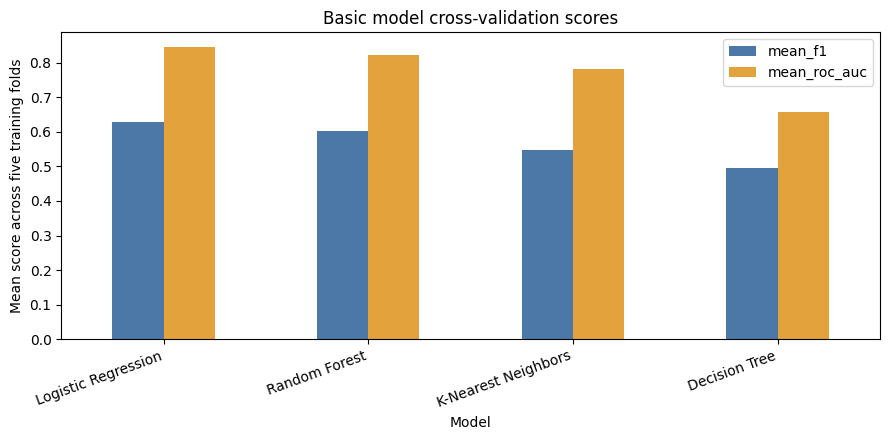

In [11]:
basic_cv_results.set_index("model")[["mean_f1", "mean_roc_auc"]].plot(kind="bar", figsize=(9, 4.5), color=["#4C78A8", "#E3A23B"])
plt.title("Basic model cross-validation scores")
plt.ylabel("Mean score across five training folds")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 7. Tune a few model settings

A model learns parameters from training data. Hyperparameters are settings we choose before fitting, such as tree depth or the amount of regularization. GridSearchCV tries every combination in a small grid. RandomizedSearchCV samples a limited number of combinations from a range.

The searches use five-fold cross-validation on the training portion only. F1 selects the best setting; we still record other scores for context.

In [12]:
logistic_pipeline = make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid={
        "classifier__C": [0.1, 1.0, 10.0],
        "classifier__class_weight": [None, "balanced"],
    },
    scoring=scoring,
    refit="f1",
    cv=cross_validation,
    error_score="raise",
)
logistic_search.fit(X_train, y_train)
print("Logistic Regression best settings:", logistic_search.best_params_)
print(f"Best mean CV F1: {logistic_search.best_score_:.3f}")

Logistic Regression best settings: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Best mean CV F1: 0.629


In [13]:
tree_pipeline = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
tree_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid={
        "classifier__max_depth": [4, 8, None],
        "classifier__min_samples_leaf": [1, 10],
        "classifier__class_weight": [None, "balanced"],
    },
    scoring=scoring,
    refit="f1",
    cv=cross_validation,
    error_score="raise",
)
tree_search.fit(X_train, y_train)
print("Decision Tree best settings:", tree_search.best_params_)
print(f"Best mean CV F1: {tree_search.best_score_:.3f}")

Decision Tree best settings: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 1}
Best mean CV F1: 0.603


In [14]:
forest_pipeline = make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE))
forest_search = RandomizedSearchCV(
    estimator=forest_pipeline,
    param_distributions={
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 8, 14],
        "classifier__min_samples_leaf": [1, 3, 8],
        "classifier__class_weight": ["balanced", "balanced_subsample"],
    },
    n_iter=8,
    scoring=scoring,
    refit="f1",
    cv=cross_validation,
    random_state=RANDOM_STATE,
    error_score="raise",
)
forest_search.fit(X_train, y_train)
print("Random Forest combinations tested:", forest_search.n_iter)
print("Random Forest best settings:", forest_search.best_params_)
print(f"Best mean CV F1: {forest_search.best_score_:.3f}")

Random Forest combinations tested: 8
Random Forest best settings: {'classifier__n_estimators': 300, 'classifier__min_samples_leaf': 8, 'classifier__max_depth': 8, 'classifier__class_weight': 'balanced'}
Best mean CV F1: 0.637


In [15]:
searches = {
    "Logistic Regression (tuned)": logistic_search,
    "Decision Tree (tuned)": tree_search,
    "Random Forest (tuned)": forest_search,
}
tuned_models = {name: search.best_estimator_ for name, search in searches.items()}
tuned_rows = []
for model_name, search in searches.items():
    best_index = search.best_index_
    row = {"model": model_name}
    for metric_name in scoring:
        row[f"mean_{metric_name}"] = search.cv_results_[f"mean_test_{metric_name}"][best_index]
        row[f"std_{metric_name}"] = search.cv_results_[f"std_test_{metric_name}"][best_index]
    tuned_rows.append(row)
tuned_cv_results = pd.DataFrame(tuned_rows)

default_comparison = basic_cv_results[basic_cv_results["model"].isin(["Logistic Regression", "Decision Tree", "Random Forest"])]
comparison = pd.concat([
    default_comparison[["model", "mean_f1", "std_f1"]].rename(columns={"model": "comparison", "mean_f1": "mean_f1", "std_f1": "std_f1"}),
    tuned_cv_results[["model", "mean_f1", "std_f1"]].rename(columns={"model": "comparison", "mean_f1": "mean_f1", "std_f1": "std_f1"}),
], ignore_index=True)

print("Default versus tuned F1:")
display(comparison.round(3))
print("Tuned model scores:")
display(tuned_cv_results[["model", "mean_accuracy", "mean_precision", "mean_recall", "mean_f1", "std_f1", "mean_roc_auc"]].round(3))

Default versus tuned F1:


,comparison,mean_f1,std_f1
0,Logistic Regression,0.628,0.026
1,Random Forest,0.602,0.024
2,Decision Tree,0.495,0.017
3,Logistic Regression (tuned),0.629,0.021
4,Decision Tree (tuned),0.603,0.011
5,Random Forest (tuned),0.637,0.015


Tuned model scores:


,model,mean_accuracy,mean_precision,mean_recall,mean_f1,std_f1,mean_roc_auc
0,Logistic Regression (tuned),0.751,0.520,0.798,0.629,0.021,0.846
1,Decision Tree (tuned),0.723,0.489,0.792,0.603,0.011,0.828
2,Random Forest (tuned),0.758,0.530,0.798,0.637,0.015,0.848


A tuned setting may improve a score only slightly. We will compare the tuned results with ensemble models before choosing the final pipeline. We do not use the held-out test set to select hyperparameters.

## 8. Compare ensemble learning

An ensemble combines multiple models. Random Forest is a bagging example: it averages many trees trained on varied samples. Gradient Boosting adds small trees in sequence to correct earlier errors. A soft Voting Classifier averages probability estimates from Logistic Regression, Random Forest, and Gradient Boosting.

Combining models does not guarantee better performance. We use the same training folds and scoring measures to compare the ensembles fairly.

In [16]:
ensemble_models = {
    "Random Forest (bagging)": make_pipeline(RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE
    )),
    "Gradient Boosting": make_pipeline(GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE
    )),
    "Soft Voting Classifier": make_pipeline(VotingClassifier(
        estimators=[
            ("logistic", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
            ("forest", RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=RANDOM_STATE)),
            ("boosting", GradientBoostingClassifier(n_estimators=80, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE)),
        ],
        voting="soft",
    )),
}
ensemble_cv_results = summarize_cross_validation(ensemble_models)
display(ensemble_cv_results[["model", "mean_accuracy", "mean_precision", "mean_recall", "mean_f1", "std_f1", "mean_roc_auc"]].sort_values("mean_f1", ascending=False).round(3))

,model,mean_accuracy,mean_precision,mean_recall,mean_f1,std_f1,mean_roc_auc
2,Soft Voting Classifier,0.789,0.590,0.678,0.631,0.033,0.846
0,Random Forest (bagging),0.775,0.567,0.642,0.602,0.024,0.822
1,Gradient Boosting,0.804,0.681,0.489,0.569,0.027,0.849


Stacking is another ensemble idea: it trains a separate model to combine other models' predictions. It can add complexity, so we leave it as an optional next step.

## 9. Select one model using training-fold results

We combine the baseline, tuned, and ensemble cross-validation tables. We select the highest mean F1; if two results tie, ROC-AUC breaks the tie. This decision uses only training data. Accuracy alone does not select the model.

In [17]:
all_cv_results = pd.concat([basic_cv_results, tuned_cv_results, ensemble_cv_results], ignore_index=True)
all_cv_results = all_cv_results.sort_values(["mean_f1", "mean_roc_auc"], ascending=[False, False]).reset_index(drop=True)
display(all_cv_results[["model", "mean_accuracy", "mean_precision", "mean_recall", "mean_f1", "std_f1", "mean_roc_auc"]].round(3))

candidate_models = {**basic_models, **tuned_models, **ensemble_models}
selected_row = all_cv_results.iloc[0]
selected_model_name = selected_row["model"]
selected_model = candidate_models[selected_model_name]
print("Selected model:", selected_model_name)
print(f"Mean training CV F1: {selected_row['mean_f1']:.3f} ± {selected_row['std_f1']:.3f}")

,model,mean_accuracy,mean_precision,mean_recall,mean_f1,std_f1,mean_roc_auc
0,Random Forest (tuned),0.758,0.530,0.798,0.637,0.015,0.848
1,Soft Voting Classifier,0.789,0.590,0.678,0.631,0.033,0.846
2,Logistic Regression (tuned),0.751,0.520,0.798,0.629,0.021,0.846
3,Logistic Regression,0.748,0.517,0.801,0.628,0.026,0.846
4,Decision Tree (tuned),0.723,0.489,0.792,0.603,0.011,0.828
5,Random Forest,0.775,0.567,0.642,0.602,0.024,0.822
6,Random Forest (bagging),0.775,0.567,0.642,0.602,0.024,0.822
7,Gradient Boosting,0.804,0.681,0.489,0.569,0.027,0.849
8,K-Nearest Neighbors,0.765,0.560,0.535,0.547,0.017,0.783
9,Decision Tree,0.736,0.504,0.487,0.495,0.017,0.657


Selected model: Random Forest (tuned)
Mean training CV F1: 0.637 ± 0.015


## 10. Final test check

We now fit the chosen pipeline on all training customers and use the held-out test customers once. Precision measures how many flagged customers really churned. Recall measures how many churners we found. A false positive may mean an unnecessary contact; a false negative may mean a missed opportunity to retain someone.

In [18]:
selected_model.fit(X_train, y_train)
test_predictions = selected_model.predict(X_test)
positive_index = list(selected_model.named_steps["classifier"].classes_).index(1)
test_probabilities = selected_model.predict_proba(X_test)[:, positive_index]

final_metrics = {
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(y_test, test_predictions, zero_division=0),
    "recall": recall_score(y_test, test_predictions, zero_division=0),
    "f1_score": f1_score(y_test, test_predictions, zero_division=0),
    "roc_auc": roc_auc_score(y_test, test_probabilities),
}
display(pd.DataFrame([final_metrics], index=[selected_model_name]).round(3))

,accuracy,precision,recall,f1_score,roc_auc
Random Forest (tuned),0.753,0.523,0.797,0.631,0.844


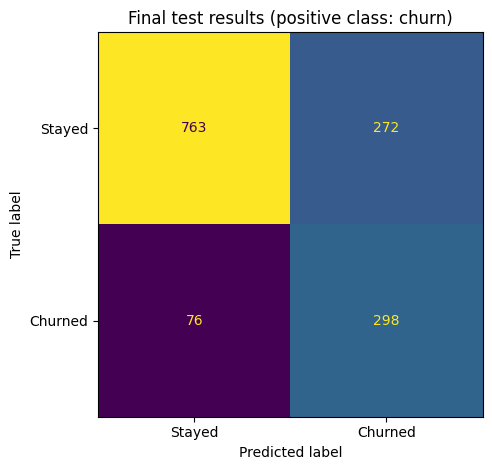

              precision    recall  f1-score   support

      Stayed      0.909     0.737     0.814      1035
     Churned      0.523     0.797     0.631       374

    accuracy                          0.753      1409
   macro avg      0.716     0.767     0.723      1409
weighted avg      0.807     0.753     0.766      1409



In [19]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Stayed", "Churned"],
    colorbar=False,
)
plt.title("Final test results (positive class: churn)")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Stayed", "Churned"],
    zero_division=0,
    digits=3,
))

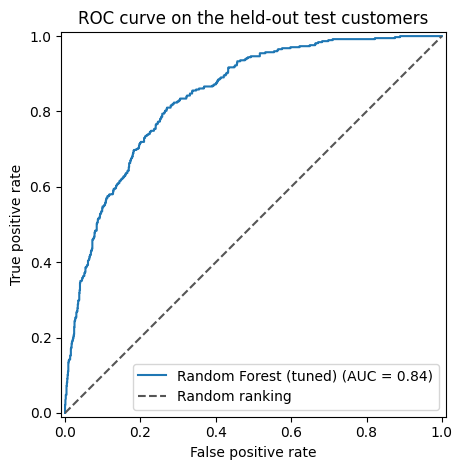

In [20]:
RocCurveDisplay.from_predictions(y_test, test_probabilities, name=selected_model_name)
plt.plot([0, 1], [0, 1], linestyle="--", color="#555555", label="Random ranking")
plt.title("ROC curve on the held-out test customers")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

The model uses a default probability cutoff of 0.50 for `predict`. Lower cutoffs generally flag more customers and can find more churners, but may also create more false positives. A business should choose a cutoff using contact capacity, retention costs, and measured campaign results.

## 11. Simple model interpretation and save

For a Random Forest, feature importance shows which encoded features the fitted trees used most for their splits. It does not prove that a feature causes churn. Related columns may share importance.

,importance
categories__Contract_Month-to-month,0.163
numbers__tenure,0.122
numbers__TotalCharges,0.081
categories__Contract_Two year,0.080
categories__OnlineSecurity_No,0.074
categories__InternetService_Fiber optic,0.059
categories__TechSupport_No,0.059
numbers__MonthlyCharges,0.048
categories__PaymentMethod_Electronic check,0.043
categories__Contract_One year,0.022


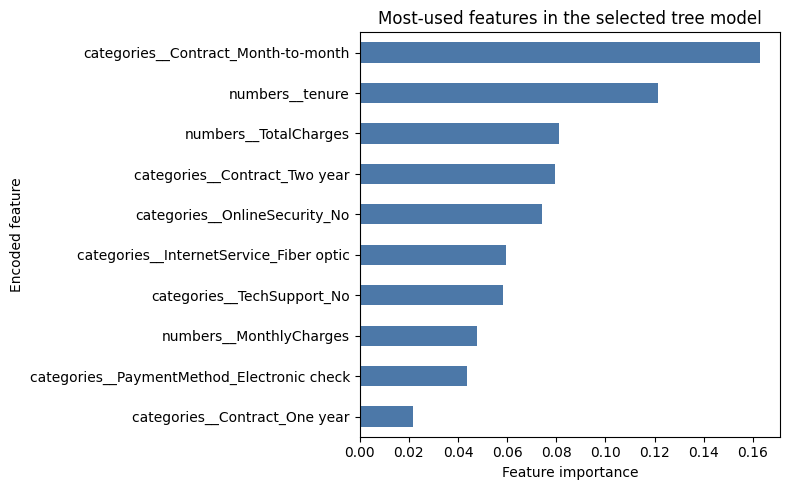

In [21]:
final_classifier = selected_model.named_steps["classifier"]
if hasattr(final_classifier, "feature_importances_"):
    feature_names = selected_model.named_steps["preprocessing"].get_feature_names_out()
    feature_importance = pd.Series(final_classifier.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
    display(feature_importance.rename("importance").to_frame().round(3))
    feature_importance.sort_values().plot(kind="barh", color="#4C78A8", figsize=(8, 5))
    plt.title("Most-used features in the selected tree model")
    plt.xlabel("Feature importance")
    plt.ylabel("Encoded feature")
    plt.tight_layout()
    plt.show()
else:
    print("This selected model does not provide one simple feature-importance list.")

In [22]:
joblib.dump(selected_model, MODEL_PATH)
relative_model_path = MODEL_PATH.relative_to(PROJECT_FOLDER).as_posix()
print(f"Saved the fitted preprocessing and model pipeline to: {relative_model_path}")
print("The API will load this same pipeline so preprocessing stays consistent.")

Saved the fitted preprocessing and model pipeline to: models/churn_model.joblib
The API will load this same pipeline so preprocessing stays consistent.


## What we learned

We used one train/test split for the whole project. Cross-validation, tuning, and ensemble comparisons were all performed inside the training portion; they did not create extra saved data splits. The final test metrics describe this held-out sample and do not prove that a retention campaign will save customers.

The next step is the small `app.py` API, which loads `churn_model.joblib` and returns a prediction and probability for one customer.